# LogBERT V3 — généralisation BGL + rigueur multi-seed

V3 reprend V2 à l'identique (même dépôt officiel au commit `a845e61`, même scoring paper-style top-`g`/`r`, même protocole : train normal-only, sélection sur validation, test verrouillé) et ajoute deux exigences : (1) un second dataset de nature différente, **BGL** (supercalculateur BlueGene/L, fenêtres temporelles de 5 min, séquences longues ~562 vs ~19 pour HDFS) ; (2) la répétition **multi-seed** à splits figés, avec moyenne ± écart-type.

Réglages officiels BGL : `m=0.5`, fenêtre 5 min / pas 1 min, `train_ratio=0.4` (shuffle seed 12), 200 époques max + arrêt précoce 10, batch 32, `seq_len=512`, `min_len=10`, 15 candidats. V3 teste `m ∈ {0.35, 0.50, 0.65}` autour du réglage officiel, puis répète le `m` sélectionné sur 3 seeds.

Baseline article BGL (Guo et al., 2021) : Precision 89.40 %, Recall 92.32 %, F1 90.83 % (référence indicative non appariée).

Exécution par phases, avec reprise des checkpoints existants : **Phase A** (ablation `m`, seed 1234), **Phase B** (multi-seed sur le `m` sélectionné), **Phase C** (optionnelle : seeds HDFS supplémentaires, désactivée par défaut).


## 1. Dépendances et dépôt officiel

Même base que V2 : on garde le Torch de Kaggle, on fixe pandas compatible NumPy 2.x, on clone le dépôt officiel au commit gelé. GPU requis.


In [ ]:
# Garder la version Torch fournie par Kaggle; installer seulement les dépendances de parsing/évaluation.
%pip install -q --force-reinstall --no-deps pandas==2.2.3
%pip install -q --no-deps regex==2023.12.25
print('Dépendances installées. Si NumPy/Pandas étaient déjà importés, redémarrer le kernel Kaggle avant de poursuivre.')

import os, sys, json, ast, random, shutil, subprocess, importlib.util
from pathlib import Path
import numpy as np
if int(np.__version__.split(".")[0]) < 2:
    raise RuntimeError(f"NumPy {np.__version__} requis en 2.x avec ce notebook.")
print("Runtime NumPy", np.__version__)
import pandas as pd
import torch
REQUIRE_GPU = True
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError("GPU non détecté. Dans Kaggle : Settings > Accelerator > GPU, puis relancer le notebook.")
print("GPU actif :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "aucun (bloqué)")
for _name, _value in {"float": float, "int": int, "Inf": np.inf}.items():
    if not hasattr(np, _name):
        setattr(np, _name, _value)
if "torch._six" not in sys.modules:
    import types
    _torch_six = types.ModuleType("torch._six")
    _torch_six.string_classes = (str,)
    _torch_six.int_classes = (int,)
    sys.modules["torch._six"] = _torch_six
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score

BASE_SEED = 1234
random.seed(BASE_SEED); np.random.seed(BASE_SEED); torch.manual_seed(BASE_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(BASE_SEED)

REPO_URL = "https://github.com/HelenGuohx/LogBERT.git"
REPO_COMMIT = "a845e612e919a6930065b69a40098eaaac26e1a3"
WORK_DIR = Path(os.environ.get("LOGBERT_WORK_DIR", str(Path.cwd() / ".logbert_v3_bgl"))).expanduser().resolve()
WORK_DIR.mkdir(parents=True, exist_ok=True)
REPO_DIR = WORK_DIR / "LogBERT"
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", REPO_COMMIT], check=True)
sys.path.insert(0, str(REPO_DIR))
print("Repository:", REPO_DIR, "| commit:", subprocess.check_output(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip())
print("Torch:", torch.__version__)

# V3 protocol constants (frozen before any training).
V3_M_GRID = [0.35, 0.50, 0.65]          # around the official BGL default m=0.50
V3_SEEDS = [1234, 2026, 999]            # Phase A uses 1234; Phase B adds the other two
V3_G_GRID_FULL = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
V3_R_GRID = np.arange(0.0, 0.801, 0.01)
V3_TARGET_PREVALENCE = 2630 / (10045 + 2630)   # paper BGL test prevalence (~20.75 %)
PAPER_BGL = {"version": "Article LogBERT BGL", "Precision": .8940, "Recall": .9232, "F1": .9083,
             "ROC_AUC": float("nan"), "PR_AUC": float("nan")}
HDFS_V2_REF = {"version": "V2 HDFS m=.75,g=8,r=.04", "Precision": .8267, "Recall": .8362,
               "F1": .8314, "ROC_AUC": .9235, "PR_AUC": .7051}
RUN_PHASE_A = True    # m ablation, seed 1234
RUN_PHASE_B = True    # multi-seed on selected m (needs Phase A selection)
RUN_PHASE_C = False   # extra HDFS seeds; needs HDFS files from the V2 session
print("V3 config:", {"m_grid": V3_M_GRID, "seeds": V3_SEEDS, "target_prevalence": round(V3_TARGET_PREVALENCE, 4)})


## 2. Trouver ou télécharger BGL

Le notebook cherche d'abord un `BGL.log` attaché (`BGL_LOG_PATH`, `/kaggle/input`, `/content`). Sinon il télécharge l'archive officielle LogHub `BGL.zip` (57 489 019 octets, MD5 vérifié) et en extrait `BGL.log`. BGL porte ses labels dans le log lui-même (préfixe `-` = normal), aucun fichier de labels séparé n'est requis.


In [ ]:
explicit_bgl = os.environ.get("BGL_LOG_PATH")
if explicit_bgl:
    BGL_LOG = Path(explicit_bgl).expanduser().resolve()
else:
    roots = [Path("/kaggle/input"), Path("/content"), Path.cwd()]
    if os.environ.get("BGL_INPUT_DIR"):
        roots.insert(0, Path(os.environ["BGL_INPUT_DIR"]).expanduser())
    roots = list(dict.fromkeys(r.resolve() for r in roots if r.exists()))
    found = [p for root in roots for p in root.rglob("*")
             if p.is_file() and p.name == "BGL.log" and p.stat().st_size >= 100_000_000]
    BGL_LOG = found[0] if found else None
    if BGL_LOG is None:
        import hashlib, urllib.request, zipfile
        download_dir = WORK_DIR / "downloaded_bgl"
        download_dir.mkdir(parents=True, exist_ok=True)
        archive_path = download_dir / "BGL.zip"
        bgl_target = download_dir / "BGL.log"
        archive_url = "https://zenodo.org/records/8196385/files/BGL.zip?download=1"
        expected_size, expected_md5 = 57489019, "4452953c470f2d95fcb32d5f6e733f7a"
        if not bgl_target.exists():
            print("BGL.log introuvable localement ; téléchargement LogHub officiel (~57 Mo)...")
            digest = hashlib.md5()
            request = urllib.request.urlopen(archive_url, timeout=120)
            with archive_path.open("wb") as output:
                while True:
                    chunk = request.read(1024 * 1024)
                    if not chunk:
                        break
                    output.write(chunk)
                    digest.update(chunk)
            if archive_path.stat().st_size != expected_size or digest.hexdigest() != expected_md5:
                raise IOError("Archive BGL.zip non conforme (taille ou MD5).")
            with zipfile.ZipFile(archive_path) as archive:
                member = next(n for n in archive.namelist() if n.endswith("BGL.log"))
                with archive.open(member) as src, bgl_target.open("wb") as dst:
                    shutil.copyfileobj(src, dst, length=8 * 1024 * 1024)
            print("BGL.log extrait :", bgl_target, f"{bgl_target.stat().st_size / 1e9:.2f} Go")
        BGL_LOG = bgl_target
print("BGL.log :", BGL_LOG, f"{BGL_LOG.stat().st_size / 1e9:.2f} Go")


## 3. Parsing Drain officiel BGL et sessionnisation (fenêtres 5 min)

On appelle `parse_log` du dépôt officiel (Drain `depth=3`, `st=0.3`, masques hexadécimaux/IP/numériques), puis on réplique exactement le bloc `__main__` officiel : labels (`-` = normal), fenêtres glissantes 5 min / pas 1 min via `logdeep`, shuffle seed 12, `train_ratio=0.4`. Le split officiel train/test est conservé ; on y ajoute une validation explicite (10 % des normales restantes, 20 % des anomalies), disjointe du train et du test, pour la sélection sans fuite.


In [ ]:
REPO_BGL = REPO_DIR / "BGL"
OUTPUT_BGL = REPO_DIR / "output" / "bgl"
OUTPUT_BGL.mkdir(parents=True, exist_ok=True)
(OUTPUT_BGL / "bert").mkdir(parents=True, exist_ok=True)
print("Contenu BGL officiel :", sorted(p.name for p in REPO_BGL.iterdir()))

DATA_HOME = Path.home() / ".dataset" / "bgl"
DATA_HOME.mkdir(parents=True, exist_ok=True)
target = DATA_HOME / "BGL.log"
if target.exists() or target.is_symlink():
    target.unlink()
target.symlink_to(BGL_LOG)

spec_bgl = importlib.util.spec_from_file_location("bgl_data_process", REPO_BGL / "data_process.py")
dp_bgl = importlib.util.module_from_spec(spec_bgl)
spec_bgl.loader.exec_module(dp_bgl)
from logdeep.dataset.session import sliding_window

# Official Drain parsing (4.7 M lines: this is the long step, run once).
dp_bgl.parse_log(str(DATA_HOME) + "/", str(OUTPUT_BGL) + "/", "BGL.log", "drain")

STRUCTURED_BGL = OUTPUT_BGL / "BGL.log_structured.csv"
assert STRUCTURED_BGL.exists(), "Parsing BGL sans sortie structurée."
df = pd.read_csv(STRUCTURED_BGL)
print("Structured:", len(df), "lignes,", df.EventId.nunique(), "clés brutes.")

# Exact official __main__ transformation, then our explicit validation split.
df["datetime"] = pd.to_datetime(df["Time"], format="%Y-%m-%d-%H.%M.%S.%f")
df["Label"] = df["Label"].apply(lambda x: int(x != "-"))
df["timestamp"] = df["datetime"].values.astype(np.int64) // 10 ** 9
df["deltaT"] = (df["datetime"].diff() / np.timedelta64(1, "s")).fillna(0)
windows = sliding_window(df[["timestamp", "Label", "EventId", "deltaT"]],
                         para={"window_size": 5 * 60, "step_size": 1 * 60})
print("Fenêtres 5 min / pas 1 min :", len(windows))

normal_all = windows[windows.Label == 0].sample(frac=1, random_state=12).reset_index(drop=True)
anomaly_all = windows[windows.Label == 1].reset_index(drop=True)
BGL_TRAIN_RATIO = 0.4  # official BGL setting
train_len = int(len(normal_all) * BGL_TRAIN_RATIO)
bgl_train = normal_all.iloc[:train_len].reset_index(drop=True)
remaining_normal = normal_all.iloc[train_len:].reset_index(drop=True)
n_val_n = int(len(remaining_normal) * 0.10)
n_val_a = int(len(anomaly_all) * 0.20)
bgl_val_normal = remaining_normal.iloc[:n_val_n].reset_index(drop=True)
bgl_test_normal = remaining_normal.iloc[n_val_n:].reset_index(drop=True)
bgl_val_anomaly = anomaly_all.iloc[:n_val_a].reset_index(drop=True)
bgl_test_anomaly = anomaly_all.iloc[n_val_a:].reset_index(drop=True)

MIN_LEN = 10  # official predictor setting, same as V2
def keep_eligible(frame):
    return frame[frame.EventId.map(len) >= MIN_LEN].reset_index(drop=True)
bgl_train, bgl_val_normal, bgl_test_normal = map(keep_eligible, [bgl_train, bgl_val_normal, bgl_test_normal])
bgl_val_anomaly, bgl_test_anomaly = map(keep_eligible, [bgl_val_anomaly, bgl_test_anomaly])
assert (bgl_train.Label == 0).all()

def write_bgl_sequences(frame, filename):
    path = OUTPUT_BGL / filename
    with path.open("w", encoding="utf-8") as stream:
        for events in frame.EventId:
            stream.write(" ".join(map(str, events)) + " \n")
    return path

for frame, name in [(bgl_train, "train"), (bgl_val_normal, "val_normal"), (bgl_val_anomaly, "val_abnormal"),
                    (bgl_test_normal, "test_normal"), (bgl_test_anomaly, "test_abnormal")]:
    write_bgl_sequences(frame, name)

def v3_file_lines(path):
    with open(path, encoding="utf-8") as f:
        return sum(1 for _ in f)
V3_BGL_FILES = {name: OUTPUT_BGL / name for name in ["train", "val_normal", "val_abnormal", "test_normal", "test_abnormal"]}
V3_BGL_COUNTS = {name: v3_file_lines(path) for name, path in V3_BGL_FILES.items()}
print("Train normal=%d ; val %d/%d ; test %d/%d" % (V3_BGL_COUNTS["train"], V3_BGL_COUNTS["val_normal"],
      V3_BGL_COUNTS["val_abnormal"], V3_BGL_COUNTS["test_normal"], V3_BGL_COUNTS["test_abnormal"]))
print("Prévalence test BGL : %.2f %%" % (100 * V3_BGL_COUNTS["test_abnormal"] / (V3_BGL_COUNTS["test_normal"] + V3_BGL_COUNTS["test_abnormal"])))
lengths = windows.EventId.map(len)
print("Longueur médiane / p95 des fenêtres :", int(lengths.median()), int(lengths.quantile(.95)))
(WORK_DIR / "v3_bgl_split.json").write_text(json.dumps({"counts": V3_BGL_COUNTS, "repo_commit": REPO_COMMIT}, indent=2))


## Phase A — Ablation contrôlée de `m` sur BGL (seed 1234)

Même grille d'esprit que V2, centrée sur le défaut officiel BGL (`m=0.5`). Entraînement repris si le checkpoint existe déjà. Le vocabulaire vient du seul train.


Ragged-array patches applied (explicit object construction, sample.py + predict_log.py).
Stale bert_pytorch modules purged: []
device cuda
features logkey:True time: False
mask ratio 0.5
arguments Namespace(vocab_size=None, encoding='utf-8', min_freq=1, mode='vocab')
Building Vocab


100%|██████████| 6681/6681 [00:01<00:00, 3556.89it/s]


vocab_size 185
Vocabulaire BGL (train only) : 185
device cuda
features logkey:True time: False
mask ratio 0.5
Grille g retenue : [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]

=== V3 training seed=1234 m=0.35 (séquences longues : étape coûteuse) ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v3_bgl/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:06<00:00, 1012.34it/s]


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


...

Epoch: 47 | phase: valid, loss=0.663437707722187
logkey loss: 0.6333510003983974, hyper loss: 0.3008670352399349

Log saved


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 48 | phase: train, loss=0.4976989015498582
logkey loss: 0.48172957139378564, hyper loss: 0.15969329187895526



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 48 | phase: valid, loss=0.646974527835846
logkey loss: 0.6232827827334404, hyper loss: 0.23691745474934578

Log saved
Early stopping


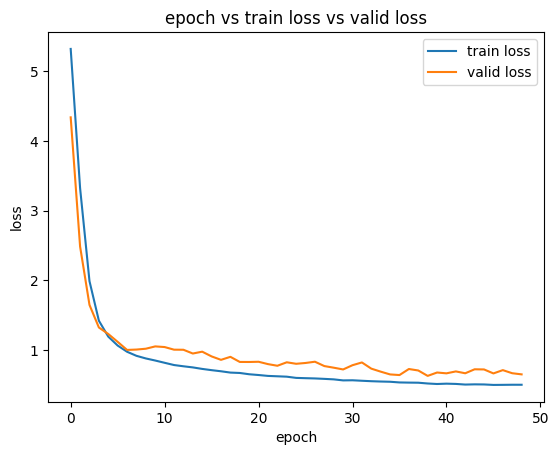

plot done

=== V3 training seed=1234 m=0.50 (séquences longues : étape coûteuse) ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v3_bgl/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:07<00:00, 933.22it/s] 


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 0 | phase: train, loss=5.3338375295547245
logkey loss: 5.207157562123263, hyper loss: 1.2667996838768536



...

Epoch: 101 | phase: valid, loss=0.5181390851736069
logkey loss: 0.5051848009228707, hyper loss: 0.12954287342727183

Log saved


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 102 | phase: train, loss=0.41783646039943645
logkey loss: 0.4088483922442491, hyper loss: 0.08988068412172603



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 102 | phase: valid, loss=0.5240409538149834
logkey loss: 0.5123513646423816, hyper loss: 0.11689588204026222

Log saved
Early stopping


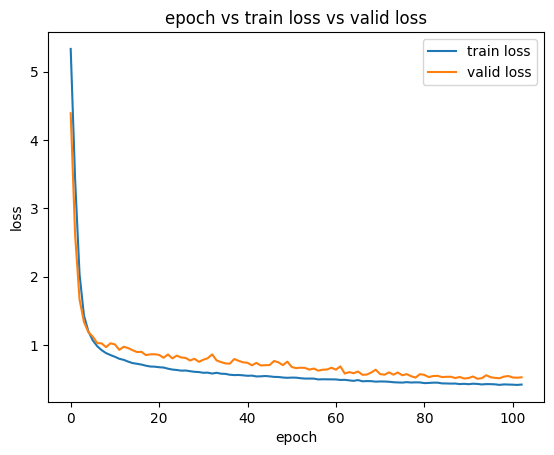

plot done

=== V3 training seed=1234 m=0.65 (séquences longues : étape coûteuse) ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v3_bgl/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:07<00:00, 944.00it/s] 


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 0 | phase: train, loss=5.345655390285553
logkey loss: 5.21983730729251, hyper loss: 1.2581807802067722



...

Epoch: 134 | phase: valid, loss=0.5303332604467869
logkey loss: 0.5216524749994278, hyper loss: 0.08680785149335861

Log saved


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 135 | phase: train, loss=0.4448377262940381
logkey loss: 0.43790722812680316, hyper loss: 0.06930498460078621



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 135 | phase: valid, loss=0.5251977898180484
logkey loss: 0.5162577264010906, hyper loss: 0.08940057270228863

Log saved
Early stopping


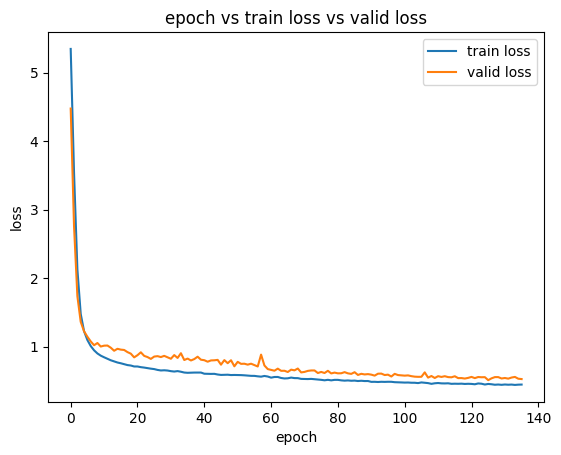

plot done
Phase A terminée : [0.35, 0.5, 0.65]


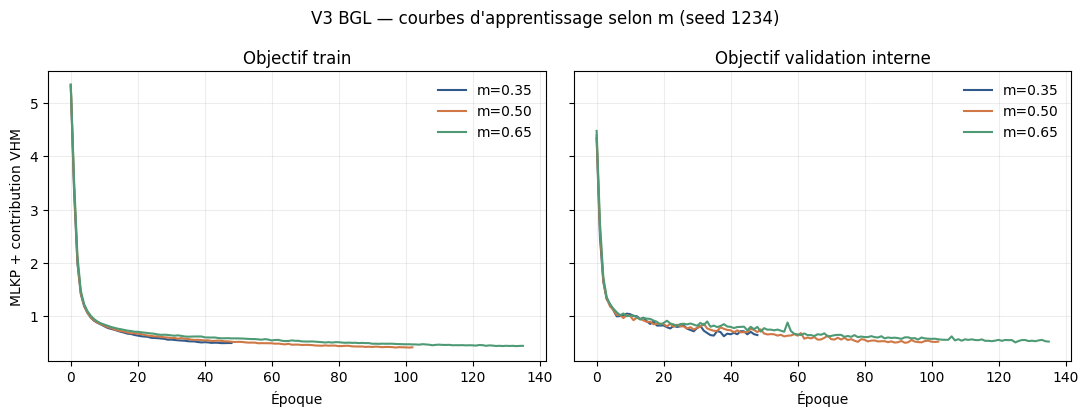

In [6]:
import random
import subprocess
import matplotlib.pyplot as plt

# Bulletproof NumPy-2 ragged fix: explicit object-array construction.
# np.array(ragged, dtype=object) still raises inhomogeneous-shape on NumPy 2.x
# when elements are ndarrays (BGL long windows) — plain element assignment never does.
import re as _re
_OBJECT_TMP = {"logkey_seq_pairs": "_tmp_logkey", "time_seq_pairs": "_tmp_time",
               "log_seqs": "_tmp_logseq", "tim_seqs": "_tmp_timseq"}
_PATCH_FILES = {
    REPO_DIR / "bert_pytorch" / "dataset" / "sample.py": ["logkey_seq_pairs", "time_seq_pairs"],
    REPO_DIR / "bert_pytorch" / "predict_log.py": ["log_seqs", "tim_seqs"],
}
for _path, _vars in _PATCH_FILES.items():
    _text = _path.read_text(encoding="utf-8")
    for _var in _vars:
        _tmp = _OBJECT_TMP[_var]
        if f"np.empty(len({_tmp}), dtype=object)" in _text:
            continue  # already patched (idempotent across re-runs)
        _pattern = _re.compile(rf"^([ 	]*){_var} = np\.array\({_var}(?:, dtype=object)?\)[ 	]*$", _re.M)
        _match = _pattern.search(_text)
        if not _match:
            raise RuntimeError(f"Patch target not found: {_var} in {_path.name}")
        _ind = _match.group(1)
        _block = chr(10).join([
            f"{_ind}{_tmp} = list({_var})",
            f"{_ind}{_var} = np.empty(len({_tmp}), dtype=object)",
            f"{_ind}for _i, _s in enumerate({_tmp}):",
            f"{_ind}    {_var}[_i] = _s",
            f"{_ind}del {_tmp}",
        ])
        _text = _pattern.sub(_block, _text, count=1)
    _path.write_text(_text, encoding="utf-8")
print("Ragged-array patches applied (explicit object construction, sample.py + predict_log.py).")
# Without this, an already-imported bert_pytorch (previous failed run) would shadow
# the patched files and replay the old bytecode. Purge, then import fresh.
for _mod in [m for m in list(sys.modules) if m == "bert_pytorch" or m.startswith("bert_pytorch.")]:
    del sys.modules[_mod]
print("Stale bert_pytorch modules purged:", [m for m in sys.modules if m.startswith("bert_pytorch")])
from bert_pytorch import Trainer
from bert_pytorch.dataset.utils import seed_everything

subprocess.run([sys.executable, "logbert.py", "vocab"], cwd=REPO_BGL, check=True)
from bert_pytorch.dataset import WordVocab
v3_vocab_path = OUTPUT_BGL / "vocab.pkl"
v3_vocab = WordVocab.load_vocab(str(v3_vocab_path))
print("Vocabulaire BGL (train only) :", len(v3_vocab))

spec_v3 = importlib.util.spec_from_file_location("bgl_logbert_v3_config", REPO_BGL / "logbert.py")
cfg_v3 = importlib.util.module_from_spec(spec_v3)
spec_v3.loader.exec_module(cfg_v3)
V3_G_GRID = [g for g in V3_G_GRID_FULL if g <= len(v3_vocab)]
print("Grille g retenue :", V3_G_GRID)

def v3_train_model(seed, mask_ratio, base_options=None):
    """Train (or reload) one BGL model. Splits stay fixed; only init/training vary with seed."""
    tag = f"m{mask_ratio:.2f}".replace(".", "p")
    model_dir = OUTPUT_BGL / "v3" / f"seed{seed}" / tag
    model_dir.mkdir(parents=True, exist_ok=True)
    options = (base_options or cfg_v3.options).copy()
    options.update({
        "device": "cuda" if torch.cuda.is_available() else "cpu",
        "output_dir": str(OUTPUT_BGL) + "/",
        "model_dir": str(model_dir) + "/",
        "model_path": str(model_dir / "best_bert.pth"),
        "vocab_path": str(v3_vocab_path),
        "scale_path": str(model_dir / "scale.pkl"),
        "mask_ratio": mask_ratio,
        "num_workers": 2,
        "on_memory": True,
    })
    seed_everything(seed=seed)
    checkpoint = Path(options["model_path"])
    if checkpoint.exists():
        print(f"Checkpoint existant seed={seed} m={mask_ratio:.2f} : reprise sans réentraînement.")
    else:
        print(f"\n=== V3 training seed={seed} m={mask_ratio:.2f} (séquences longues : étape coûteuse) ===")
        trainer = Trainer(options)
        trainer.train()
        del trainer
        if not checkpoint.exists():
            raise FileNotFoundError(f"Checkpoint manquant seed={seed} m={mask_ratio}")
    try:
        model = torch.load(str(checkpoint), map_location=options["device"], weights_only=False)
    except TypeError:
        model = torch.load(str(checkpoint), map_location=options["device"])
    model.to(options["device"]); model.eval()
    return model, options

V3A_MODELS, V3A_OPTIONS = {}, {}
if RUN_PHASE_A:
    for mask_ratio in V3_M_GRID:
        model, options = v3_train_model(V3_SEEDS[0], mask_ratio)
        V3A_MODELS[mask_ratio] = model
        V3A_OPTIONS[mask_ratio] = options
        del model
    print("Phase A terminée :", sorted(V3A_OPTIONS))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    colors = ["#315A8A", "#D07845", "#4E9A75"]
    for index, mask_ratio in enumerate(V3_M_GRID):
        log_dir = OUTPUT_BGL / "v3" / f"seed{V3_SEEDS[0]}" / f"m{mask_ratio:.2f}".replace(".", "p")
        train_log = pd.read_csv(log_dir / "train_log2.csv")
        valid_log = pd.read_csv(log_dir / "valid_log2.csv")
        axes[0].plot(train_log.epoch, train_log.loss, color=colors[index % 3], label=f"m={mask_ratio:.2f}")
        axes[1].plot(valid_log.epoch, valid_log.loss, color=colors[index % 3], label=f"m={mask_ratio:.2f}")
    axes[0].set_title("Objectif train"); axes[1].set_title("Objectif validation interne")
    for ax in axes:
        ax.set_xlabel("Époque"); ax.grid(alpha=.22); ax.legend(frameon=False)
    axes[0].set_ylabel("MLKP + contribution VHM")
    fig.suptitle("V3 BGL — courbes d'apprentissage selon m (seed 1234)")
    fig.tight_layout(); fig.savefig(WORK_DIR / "logbert_v3_loss_curves.png", dpi=220, bbox_inches="tight"); plt.show()
else:
    print("RUN_PHASE_A=False : ablation sautée.")


## Phase A — Sélection validation-only de `m`, `g`, `r`, puis test verrouillé BGL

Même scoring paper-style que V2 (erreurs hors top-`g` indépendantes, `r` en proportion). Seul le triplet sélectionné sur validation est scoré sur le test BGL.


In [7]:
from bert_pytorch.dataset import LogDataset
from bert_pytorch import Predictor
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from scipy.stats import norm

def v3_scores_by_g(model, options, vocab, filename, seed, g_grid):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    predictor = Predictor(options)
    log_seqs, time_seqs = predictor.generate_test(
        options["output_dir"], filename, predictor.window_size,
        predictor.adaptive_window, predictor.seq_len, None, predictor.min_len)
    dataset = LogDataset(log_seqs, time_seqs, vocab, seq_len=predictor.seq_len,
                         corpus_lines=predictor.corpus_lines, on_memory=False,
                         predict_mode=True, mask_ratio=options["mask_ratio"])
    loader = DataLoader(dataset, batch_size=predictor.batch_size,
                        num_workers=predictor.num_workers, collate_fn=dataset.collate_fn)
    errors = {g: [] for g in g_grid}
    n_masked_by_sequence = []
    for batch_index, batch in enumerate(loader):
        batch = {key: value.to(options["device"]) for key, value in batch.items()}
        with torch.no_grad():
            logits = model(batch["bert_input"], batch["time_input"])["logkey_output"]
        labels = batch["bert_label"]
        for i in range(len(labels)):
            mask = labels[i] > 0
            target = labels[i][mask]
            masked_logits = logits[i][mask]
            n_masked = len(target)
            n_masked_by_sequence.append(n_masked)
            if n_masked:
                top_ids = torch.topk(masked_logits, k=max(g_grid), dim=-1).indices
                matches = top_ids == target.unsqueeze(1)
                for g in g_grid:
                    errors[g].append(int((~matches[:, :g].any(dim=1)).sum().item()))
            else:
                for g in g_grid:
                    errors[g].append(0)
        if batch_index and batch_index % 500 == 0 and batch_index:
            print(f"{filename}: {sum(n_masked_by_sequence):,} masked positions")
    denominator = np.maximum(np.asarray(n_masked_by_sequence, dtype=float), 1)
    return {g: np.asarray(errors[g], dtype=float) / denominator for g in g_grid}

def v3_threshold_metrics(y, score, r, prior):
    pred = (score > r).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    recall = tp / max(tp + fn, 1)
    fpr = fp / max(fp + tn, 1)
    precision_target = prior * recall / max(prior * recall + (1 - prior) * fpr, 1e-12)
    f1_target = 2 * precision_target * recall / max(precision_target + recall, 1e-12)
    return {"Precision_target": precision_target, "Recall": recall, "F1_target": f1_target,
            "FPR": fpr, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}

def v3_wilson(successes, total, confidence=0.95):
    if total <= 0:
        return [float("nan"), float("nan")]
    z = norm.ppf(.5 + confidence / 2); p = successes / total; den = 1 + z * z / total
    center = (p + z * z / (2 * total)) / den
    half = z * np.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / den
    return [max(0., center - half), min(1., center + half)]

def v3_select_triplet(model_by_m, options_by_m, vocab, counts, g_grid, r_grid, prior):
    y_val = np.r_[np.zeros(counts["val_normal"], dtype=int), np.ones(counts["val_abnormal"], dtype=int)]
    rows, scores = [], {}
    for m, model in model_by_m.items():
        opts = options_by_m[m]
        val_n = v3_scores_by_g(model, opts, vocab, "val_normal", 1234, g_grid)
        val_a = v3_scores_by_g(model, opts, vocab, "val_abnormal", 1235, g_grid)
        scores[m] = (val_n, val_a)
        for g in g_grid:
            score = np.r_[val_n[g], val_a[g]]
            for r in r_grid:
                rows.append({"m": m, "g": g, "r": float(r), **v3_threshold_metrics(y_val, score, r, prior)})
    search = pd.DataFrame(rows)
    best = search.sort_values(["F1_target", "Recall", "Precision_target"], ascending=False).iloc[0]
    return {"m": float(best.m), "g": int(best.g), "r": float(best.r),
            "validation_F1_target": float(best.F1_target),
            "validation_precision_target": float(best.Precision_target),
            "validation_recall": float(best.Recall)}, search

def v3_score_locked_test(model, options, vocab, g, r, counts):
    y_test = np.r_[np.zeros(counts["test_normal"], dtype=int), np.ones(counts["test_abnormal"], dtype=int)]
    test_n = v3_scores_by_g(model, options, vocab, "test_normal", 1236, [g])
    test_a = v3_scores_by_g(model, options, vocab, "test_abnormal", 1237, [g])
    scores = np.r_[test_n[g], test_a[g]]
    pred = (scores > r).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {"m": float(options["mask_ratio"]), "g": int(g), "r": float(r),
            "Precision": float(precision_score(y_test, pred, zero_division=0)),
            "Recall": float(recall_score(y_test, pred, zero_division=0)),
            "F1": float(f1_score(y_test, pred, zero_division=0)),
            "FPR": float(fp / max(tn + fp, 1)), "TP": int(tp), "FP": int(fp),
            "FN": int(fn), "TN": int(tn),
            "ROC_AUC": float(roc_auc_score(y_test, scores)),
            "PR_AUC": float(average_precision_score(y_test, scores)),
            "test_prevalence": float(y_test.mean()),
            "Precision_CI95": v3_wilson(tp, tp + fp), "Recall_CI95": v3_wilson(tp, tp + fn)}, scores, y_test

if RUN_PHASE_A:
    V3A_MODELS, V3A_OPTIONS = {}, {}
    for m in V3_M_GRID:
        _model, _options = v3_train_model(V3_SEEDS[0], m)
        V3A_MODELS[m], V3A_OPTIONS[m] = _model, _options
        del _model
    V3A_SELECTION, v3a_search = v3_select_triplet(V3A_MODELS, V3A_OPTIONS, v3_vocab, V3_BGL_COUNTS,
                                                  V3_G_GRID, V3_R_GRID, V3_TARGET_PREVALENCE)
    print("V3 Phase A sélection validation :", V3A_SELECTION)
    v3a_search.to_csv(WORK_DIR / "v3_bgl_search_seed1234.csv", index=False)
    V3A_BEST = V3A_SELECTION
    best_model_a = V3A_MODELS[V3A_BEST["m"]]
    V3A_TEST, v3a_scores, v3a_y = v3_score_locked_test(best_model_a, V3A_OPTIONS[V3A_BEST["m"]],
                                                       v3_vocab, V3A_BEST["g"], V3A_BEST["r"], V3_BGL_COUNTS)
    print("V3 Phase A test verrouillé :")
    print(pd.DataFrame([V3A_TEST]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(pd.DataFrame([PAPER_BGL, {"version": f"V3 BGL m={V3A_BEST['m']:.2f},g={V3A_BEST['g']},r={V3A_BEST['r']:.2f}", **{k: V3A_TEST[k] for k in ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]}}]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    np.savez(WORK_DIR / "v3_bgl_phaseA.npz", y_test=v3a_y, scores=v3a_scores,
             g=np.array([V3A_BEST["g"]]), r=np.array([V3A_BEST["r"]]))
else:
    print("RUN_PHASE_A=False : sélection sautée.")


Checkpoint existant seed=1234 m=0.35 : reprise sans réentraînement.
Checkpoint existant seed=1234 m=0.50 : reprise sans réentraînement.
Checkpoint existant seed=1234 m=0.65 : reprise sans réentraînement.


1010it [00:00, 1181.51it/s]

val_normal size: 1010



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
535it [00:00, 1198.20it/s]

val_abnormal size: 535


...

test_normal size: 9053



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
2091it [00:01, 1491.42it/s]

test_abnormal size: 2091



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


V3 Phase A test verrouillé :
     m  g      r  Precision  Recall     F1    FPR   TP  FP  FN   TN  ROC_AUC  PR_AUC  test_prevalence                           Precision_CI95                              Recall_CI95
0.5000 15 0.0100     0.9046  0.9158 0.9102 0.0223 1915 202 176 8851   0.9595  0.9189           0.1876 [0.8913241379002774, 0.9163741428342587] [0.9031534024334041, 0.9269810178482062]
                  version  Precision  Recall     F1  ROC_AUC  PR_AUC
      Article LogBERT BGL     0.8940  0.9232 0.9083      NaN     NaN
V3 BGL m=0.50,g=15,r=0.01     0.9046  0.9158 0.9102   0.9595  0.9189


## Phase B — Répétition multi-seed sur le `m` sélectionné

Splits figés (seed 12 + fractions fixes) : seules l'initialisation, l'entraînement et le masquage varient avec le seed. Pour chaque seed, `(g, r)` est re-sélectionné sur validation avec le protocole identique, puis le test verrouillé est scoré. Résultat : moyenne ± écart-type (n=3), sans toucher au test avant le gel par seed.



=== V3 training seed=2026 m=0.50 (séquences longues : étape coûteuse) ===
Save options parameters
Loading vocab /kaggle/working/.logbert_v3_bgl/LogBERT/output/bgl/vocab.pkl
vocab Size:  185

Loading Train Dataset
before filtering short session
train size  6013
valid size  668


100%|██████████| 6681/6681 [00:07<00:00, 917.18it/s] 


Num of train seqs 6013
Num of valid seqs 668

Loading valid Dataset
Creating Dataloader
Building BERT model
Creating BERT Trainer
Total Parameters: 2204858
Training Start


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 0 | phase: train, loss=5.164422927693249
logkey loss: 5.024119303188222, hyper loss: 1.4030362673621763



...

Epoch: 53 | phase: valid, loss=0.6896059609949589
logkey loss: 0.6661688968539238, hyper loss: 0.23437060490250589

Log saved


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 54 | phase: train, loss=0.5078564344003876
logkey loss: 0.4947037044613757, hyper loss: 0.13152730839456467



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 54 | phase: valid, loss=0.7098274625837803
logkey loss: 0.6882598049938679, hyper loss: 0.21567652150988578

Log saved
Early stopping


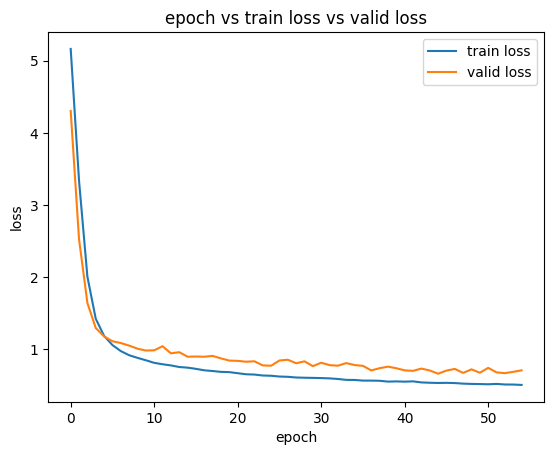

plot done


1010it [00:00, 1426.68it/s]

val_normal size: 1010



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
535it [00:00, 953.74it/s] 

val_abnormal size: 535


...

Epoch: 118 | phase: valid, loss=0.4854851208627224
logkey loss: 0.47792856246232984, hyper loss: 0.07556561678647995

Log saved


start calculate center


  0%|          | 0/187 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
  0%|          | 0/20 [00:00<?, ?it/s]/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py

Epoch: 119 | phase: train, loss=0.38820114488748303
logkey loss: 0.3820977465294421, hyper loss: 0.061033977086053175



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


Epoch: 119 | phase: valid, loss=0.47708185240626333
logkey loss: 0.46900308802723883, hyper loss: 0.08078761696815491

Log saved
Early stopping


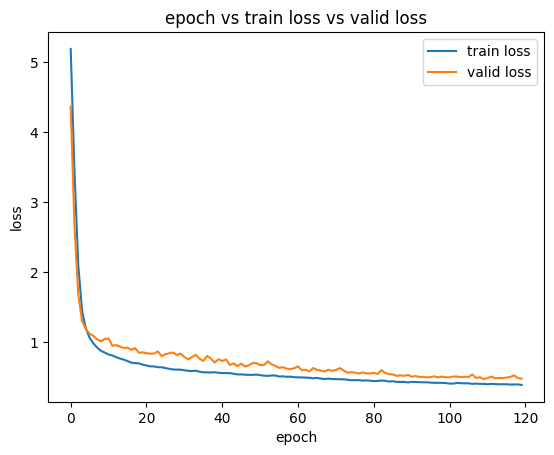

plot done


1010it [00:00, 1499.41it/s]

val_normal size: 1010



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
535it [00:00, 960.27it/s] 

val_abnormal size: 535


...

test_normal size: 9053



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
2091it [00:01, 1552.88it/s]

test_abnormal size: 2091



/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)
/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


 seed      m  g      r  Precision  Recall     F1    FPR  ROC_AUC  PR_AUC
 1234 0.5000 15 0.0100     0.9046  0.9158 0.9102 0.0223   0.9595  0.9189
 2026 0.5000 15 0.0100     0.8979  0.9168 0.9072 0.0241   0.9595  0.9187
  999 0.5000 15 0.0100     0.9112  0.9173 0.9142 0.0207   0.9597  0.9183
Moyenne ± écart-type (n=3) :
  Precision: 0.9045 ± 0.0066  [min 0.8979, max 0.9112]
  Recall: 0.9166 ± 0.0007  [min 0.9158, max 0.9173]
  F1: 0.9105 ± 0.0035  [min 0.9072, max 0.9142]
  FPR: 0.0223 ± 0.0017  [min 0.0207, max 0.0241]
  ROC_AUC: 0.9596 ± 0.0001  [min 0.9595, max 0.9597]
  PR_AUC: 0.9187 ± 0.0003  [min 0.9183, max 0.9189]
Résultats V3 sauvés : /kaggle/working/.logbert_v3_bgl/logbert_v3_bgl_results.json


In [8]:
V3B_ROWS, V3B_SCORES = [], {}
if RUN_PHASE_B:
    if "V3A_BEST" not in globals():
        raise RuntimeError("Phase B sans Phase A : relancer la sélection (RUN_PHASE_A=True) ou fixer V3A_BEST manuellement.")
    for seed in V3_SEEDS[1:]:
        model, options = v3_train_model(seed, V3A_BEST["m"])
        single_m, single_o = {V3A_BEST["m"]: model}, {V3A_BEST["m"]: options}
        sel, _ = v3_select_triplet(single_m, single_o, v3_vocab, V3_BGL_COUNTS,
                                   V3_G_GRID, V3_R_GRID, V3_TARGET_PREVALENCE)
        sel["seed"] = seed
        test_result, scores, y_test = v3_score_locked_test(model, options, v3_vocab,
                                                           sel["g"], sel["r"], V3_BGL_COUNTS)
        test_result["seed"] = seed
        test_result.update({f"sel_{k}": sel[k] for k in ["m", "g", "r", "validation_F1_target"]})
        V3B_ROWS.append(test_result)
        V3B_SCORES[seed] = {"scores": scores, "g": sel["g"], "r": sel["r"]}
        del model
    # Seed 1234 (Phase A) rejoint l'agrégat avec sa propre sélection.
    V3A_TEST["seed"] = V3_SEEDS[0]
    V3A_TEST.update({f"sel_{k}": V3A_SELECTION[k] for k in ["m", "g", "r", "validation_F1_target"]})
    V3B_SCORES[V3_SEEDS[0]] = {"scores": v3a_scores, "g": V3A_BEST["g"], "r": V3A_BEST["r"]}
    all_rows = [V3A_TEST] + V3B_ROWS
    summary = pd.DataFrame(all_rows)
    print(summary[["seed", "m", "g", "r", "Precision", "Recall", "F1", "FPR", "ROC_AUC", "PR_AUC"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    agg = {}
    for metric in ["Precision", "Recall", "F1", "FPR", "ROC_AUC", "PR_AUC"]:
        values = summary[metric].to_numpy(dtype=float)
        agg[metric] = {"mean": float(values.mean()), "std": float(values.std(ddof=1)) if len(values) > 2 else 0.0,
                       "min": float(values.min()), "max": float(values.max())}
    print("Moyenne ± écart-type (n=%d) :" % len(summary))
    for metric, stats in agg.items():
        print(f"  {metric}: {stats['mean']:.4f} ± {stats['std']:.4f}  [min {stats['min']:.4f}, max {stats['max']:.4f}]")
    (WORK_DIR / "logbert_v3_bgl_results.json").write_text(json.dumps(
        {"phaseA_selection": V3A_SELECTION, "phaseA_test": V3A_TEST, "phaseB_rows": all_rows,
         "aggregate_mean_std_n3": agg, "paper_reference": PAPER_BGL, "hdfs_v2_reference": HDFS_V2_REF,
         "seeds": V3_SEEDS, "m_grid": V3_M_GRID, "target_prevalence": V3_TARGET_PREVALENCE,
         "counts": V3_BGL_COUNTS, "repo_commit": REPO_COMMIT}, indent=2,
        default=lambda v: v.item() if hasattr(v, "item") else str(v)), encoding="utf-8")
    np.savez(WORK_DIR / "v3_bgl_phaseB.npz", y_test=y_test,
             **{f"scores_seed{s}": V3B_SCORES[s]["scores"] for s in V3B_SCORES})
    print("Résultats V3 sauvés :", WORK_DIR / "logbert_v3_bgl_results.json")
else:
    print("RUN_PHASE_B=False : multi-seed sauté.")


## Diagnostics V3 : confusion, ROC/PR par seed, comparaison croisée HDFS/BGL

Métriques au seuil gelé par seed. Aucune re-sélection sur le test.


Meilleur seed test : 999 (F1=0.9142, m=0.5, g=15, r=0.01)


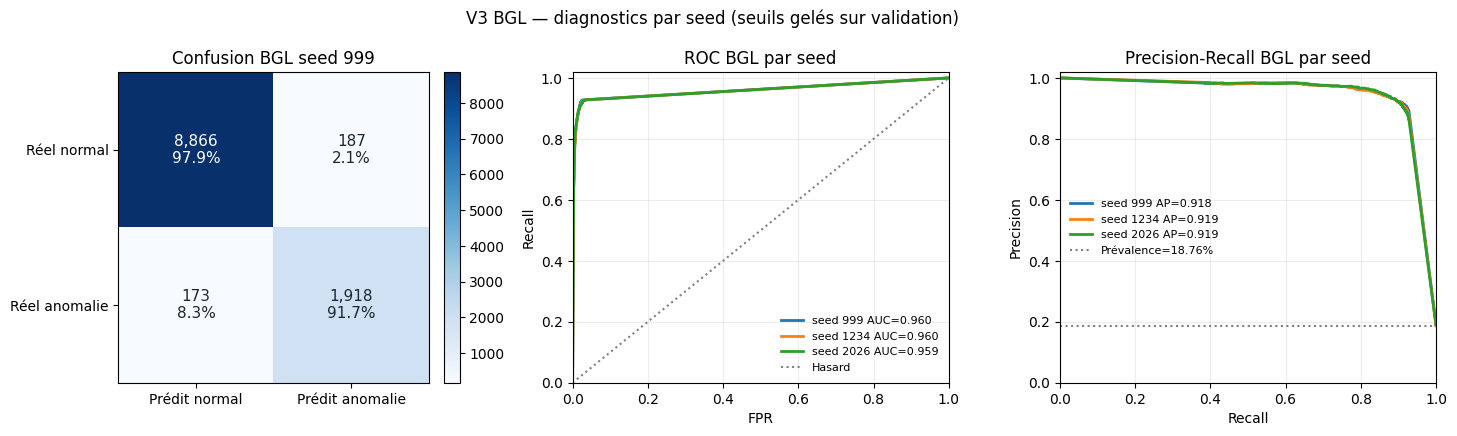

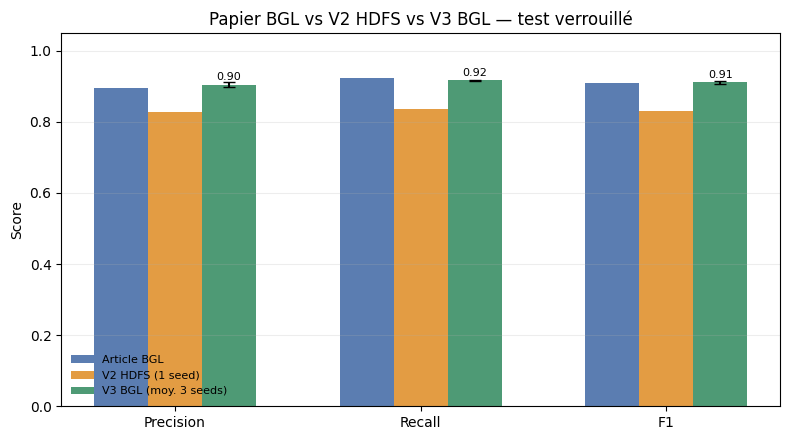

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, confusion_matrix, average_precision_score

if ("V3B_SCORES" not in globals() or not V3B_SCORES):
    if not (WORK_DIR / "logbert_v3_bgl_results.json").exists() or not (WORK_DIR / "v3_bgl_phaseB.npz").exists():
        raise RuntimeError("Aucun résultat Phase A/B en mémoire ni sur disque : exécuter les phases dans l'ordre.")
    saved = json.loads((WORK_DIR / "logbert_v3_bgl_results.json").read_text())
    archive = np.load(WORK_DIR / "v3_bgl_phaseB.npz")
    y_test_v3 = archive["y_test"]
    V3B_SCORES = {int(r["seed"]): {"scores": archive[f"scores_seed{int(r['seed'])}"], "g": int(r["g"]), "r": float(r["r"])}
                  for r in saved["phaseB_rows"]}
    V3B_ROWS_FALLBACK = saved["phaseB_rows"]
    print("Scores rechargés depuis le disque (%d seeds)." % len(V3B_SCORES))
else:
    y_test_v3 = v3a_y
    V3B_ROWS_FALLBACK = [V3A_TEST] + V3B_ROWS

best_row = max(V3B_ROWS_FALLBACK, key=lambda r: r["F1"])
best_seed = int(best_row["seed"])
print(f"Meilleur seed test : {best_seed} (F1={best_row['F1']:.4f}, m={best_row['m']}, g={best_row['g']}, r={best_row['r']})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]
cm = confusion_matrix(y_test_v3, (V3B_SCORES[best_seed]["scores"] > best_row["r"]).astype(int), labels=[0, 1])
row_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
image = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i,j]:,}\n{row_pct[i,j]:.1%}", ha="center", va="center", fontsize=11,
                color="white" if cm[i,j] > cm.max() * .55 else "#1d2733")
ax.set_xticks([0, 1], ["Prédit normal", "Prédit anomalie"])
ax.set_yticks([0, 1], ["Réel normal", "Réel anomalie"])
ax.set_title(f"Confusion BGL seed {best_seed}")
fig.colorbar(image, ax=ax, fraction=.046, pad=.04)

ax = axes[1]
for seed, pack in sorted(V3B_SCORES.items()):
    fpr_c, tpr_c, _ = roc_curve(y_test_v3, pack["scores"])
    ax.plot(fpr_c, tpr_c, linewidth=2, label=f"seed {seed} AUC={auc(fpr_c, tpr_c):.3f}")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Hasard")
ax.set(xlabel="FPR", ylabel="Recall", title="ROC BGL par seed", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=.22)

ax = axes[2]
for seed, pack in sorted(V3B_SCORES.items()):
    pr_p, pr_r, _ = precision_recall_curve(y_test_v3, pack["scores"])
    ax.plot(pr_r, pr_p, linewidth=2, label=f"seed {seed} AP={average_precision_score(y_test_v3, pack['scores']):.3f}")
ax.axhline(float(y_test_v3.mean()), color="grey", linestyle=":", label=f"Prévalence={y_test_v3.mean():.2%}")
ax.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall BGL par seed", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=.22)
fig.suptitle("V3 BGL — diagnostics par seed (seuils gelés sur validation)")
fig.tight_layout(); fig.savefig(WORK_DIR / "logbert_v3_diagnostics.png", dpi=220, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Precision", "Recall", "F1"]
x = np.arange(3); width = .22
paper_vals = [PAPER_BGL[k] for k in labels]
hdfs_vals = [HDFS_V2_REF[k] for k in labels]
bgl_means = [np.mean([r[k] for r in V3B_ROWS_FALLBACK]) for k in labels]
bgl_stds = [np.std([r[k] for r in V3B_ROWS_FALLBACK], ddof=1) if len(V3B_ROWS_FALLBACK) > 2 else 0.0 for k in labels]
ax.bar(x - width, paper_vals, width, label="Article BGL", color="#5B7DB1")
ax.bar(x, hdfs_vals, width, label="V2 HDFS (1 seed)", color="#E39C43")
bars = ax.bar(x + width, bgl_means, width, yerr=bgl_stds, capsize=4, label="V3 BGL (moy. 3 seeds)", color="#4E9A75")
for bar, val in zip(bars, bgl_means):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + .012, f"{val:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, labels); ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Papier BGL vs V2 HDFS vs V3 BGL — test verrouillé")
ax.legend(frameon=False, fontsize=8); ax.grid(axis="y", alpha=.22)
fig.tight_layout(); fig.savefig(WORK_DIR / "logbert_v3_cross_dataset.png", dpi=220, bbox_inches="tight"); plt.show()


## Export du meilleur modèle BGL et API d'inférence

Même contrat que V2 : checkpoint + vocabulaire + mapping Drain + `inference.py` générique (fonction de scoring/preuves pour le SLM). La carte des templates vient de `BGL.log_templates.csv` produit par Drain. Smoke test sur validation uniquement.


In [10]:
import os, json, shutil, zipfile, textwrap
from pathlib import Path

for _need in ["v3_train_model", "v3_vocab", "v3_vocab_path"]:
    if _need not in globals():
        raise RuntimeError("Exécuter d'abord les cellules Dépendances, Parsing et Phase A (même avec RUN_PHASE_A=False).")
if "V3B_ROWS_FALLBACK" not in globals():
    saved_bundle = json.loads((WORK_DIR / "logbert_v3_bgl_results.json").read_text())
    V3B_ROWS_FALLBACK = saved_bundle["phaseB_rows"]
best_bundle_row = max(V3B_ROWS_FALLBACK, key=lambda r: r["F1"])
BEST_SEED_BGL = int(best_bundle_row["seed"])
BEST_M_BGL, BEST_G_BGL, BEST_R_BGL = float(best_bundle_row["m"]), int(best_bundle_row["g"]), float(best_bundle_row["r"])
print(f"Export seed {BEST_SEED_BGL} : m={BEST_M_BGL}, g={BEST_G_BGL}, r={BEST_R_BGL}, F1 test={best_bundle_row['F1']:.4f}")

ARTIFACT_BGL = Path("/kaggle/working/logbert_v3_bgl_best")
if ARTIFACT_BGL.exists():
    shutil.rmtree(ARTIFACT_BGL)
ARTIFACT_BGL.mkdir(parents=True, exist_ok=True)

best_bgl_model, best_bgl_options = v3_train_model(BEST_SEED_BGL, BEST_M_BGL)
best_checkpoint_bgl = Path(best_bgl_options["model_path"])
shutil.copy2(best_checkpoint_bgl, ARTIFACT_BGL / "best_bert.pth")
shutil.copy2(v3_vocab_path, ARTIFACT_BGL / "vocab.pkl")
bgl_templates_csv = OUTPUT_BGL / "BGL.log_templates.csv"
if bgl_templates_csv.exists():
    shutil.copy2(bgl_templates_csv, ARTIFACT_BGL / "BGL.log_templates.csv")
    template_frame = pd.read_csv(bgl_templates_csv, usecols=["EventId", "EventTemplate"]).drop_duplicates("EventId")
    id_to_template_bgl = dict(zip(template_frame.EventId.astype(str), template_frame.EventTemplate.astype(str)))
else:
    id_to_template_bgl = {}
    print("Attention : BGL.log_templates.csv absent, carte des templates vide.")
event_hash_to_id_bgl = {eid: eid for eid in id_to_template_bgl}

manifest_bgl = {
    "model": "Official LogBERT BGL implementation",
    "repository": "https://github.com/HelenGuohx/LogBERT",
    "repository_commit": REPO_COMMIT,
    "dataset": "LogHub BGL full (5-min windows, 1-min step)",
    "artifact_type": "serialized full PyTorch model plus WordVocab pickle",
    "mask_ratio_m": BEST_M_BGL,
    "top_g": BEST_G_BGL,
    "sequence_threshold_r": BEST_R_BGL,
    "sequence_length": int(best_bgl_options["seq_len"]),
    "adaptive_window": bool(best_bgl_options["adaptive_window"]),
    "minimum_sequence_length": int(best_bgl_options["min_len"]),
    "prediction_rule": "anomaly iff undetected masked keys > masked keys * r",
    "input_contract": "list of per-session BGL EventId strings from the bundled Drain mapping",
    "id_to_template": id_to_template_bgl,
    "event_hash_to_id": {str(k): str(v) for k, v in event_hash_to_id_bgl.items()},
    "test_metrics": {k: v for k, v in best_bundle_row.items() if k in ["Precision", "Recall", "F1", "FPR", "TP", "FP", "FN", "TN", "ROC_AUC", "PR_AUC", "test_prevalence", "seed"]},
}
(ARTIFACT_BGL / "manifest.json").write_text(json.dumps(manifest_bgl, ensure_ascii=False, indent=2, default=lambda v: v.item() if hasattr(v, "item") else str(v)))
torch.save(best_bgl_model.state_dict(), ARTIFACT_BGL / "best_bert_state_dict.pth")

inference_source = r"""import json
from pathlib import Path
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from bert_pytorch.dataset import WordVocab, LogDataset


def load_logbert_bundle(artifact_dir, repo_commit=None, device=None):
    # Load after adding the matching official LogBERT repo to sys.path.
    from bert_pytorch import Predictor
    artifact_dir = Path(artifact_dir)
    manifest = json.loads((artifact_dir / "manifest.json").read_text())
    if repo_commit is not None and repo_commit != manifest["repository_commit"]:
        raise ValueError("LogBERT repository commit differs from exported artifact")
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    vocab = WordVocab.load_vocab(str(artifact_dir / "vocab.pkl"))
    try:
        model = torch.load(str(artifact_dir / "best_bert.pth"), map_location=device, weights_only=False)
    except TypeError:
        model = torch.load(str(artifact_dir / "best_bert.pth"), map_location=device)
    model.to(device); model.eval()
    return {"manifest": manifest, "vocab": vocab, "model": model, "device": device}


def encode_event_hashes(event_hashes, manifest):
    # Map Drain event hashes to training integer IDs; unseen hashes become OOV.
    mapping = manifest["event_hash_to_id"]
    return [mapping.get(str(event_hash), "<UNMAPPED_EVENT>") for event_hash in event_hashes]


def predict_event_sequences(event_sequences, bundle, session_ids=None, seed=2025, batch_size=64):
    # Input sequences are integer EventIds or strings from the bundled mapping.
    # Raw log lines must be parsed upstream with the compatible Drain mapping.
    manifest, vocab, model, device = (bundle[k] for k in ("manifest", "vocab", "model", "device"))
    ids = list(session_ids) if session_ids is not None else [str(i) for i in range(len(event_sequences))]
    if len(ids) != len(event_sequences):
        raise ValueError("session_ids and event_sequences length mismatch")
    minimum = int(manifest["minimum_sequence_length"])
    max_len = int(manifest["sequence_length"])
    eligible = []
    results = [None] * len(event_sequences)
    for idx, sequence in enumerate(event_sequences):
        sequence = list(map(str, sequence))[:max_len]
        if len(sequence) < minimum:
            results[idx] = {"session_id": ids[idx], "scored": False,
                            "reason": f"sequence shorter than min_len={minimum}"}
        else:
            eligible.append((idx, sequence))
    if not eligible:
        return results

    mask_ratio, top_g, threshold = (float(manifest["mask_ratio_m"]),
                                    int(manifest["top_g"]),
                                    float(manifest["sequence_threshold_r"]))
    sequences = [seq for _, seq in eligible]
    times = [[0.0] * len(seq) for seq in sequences]
    dataset = LogDataset(sequences, times, vocab, seq_len=max_len,
                         corpus_lines=len(sequences), on_memory=True,
                         predict_mode=True, mask_ratio=mask_ratio)
    generator = torch.Generator(); generator.manual_seed(seed)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                        num_workers=0, collate_fn=dataset.collate_fn, generator=generator)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    id_to_template = manifest.get("id_to_template", {})

    out_idx = 0
    for batch in loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        with torch.no_grad():
            logits = model(batch["bert_input"], batch["time_input"])["logkey_output"]
        labels = batch["bert_label"]
        for local_i in range(len(labels)):
            mask = labels[local_i] > 0
            targets = labels[local_i][mask]
            positions = torch.where(mask)[0]
            masked_logits = logits[local_i][mask]
            evidence = []
            if len(targets):
                candidates = torch.topk(masked_logits, k=top_g, dim=-1).indices
                errors = ~(candidates == targets.unsqueeze(1)).any(dim=1)
                error_count = int(errors.sum().item())
                for j in torch.where(errors)[0].tolist():
                    # LogDataset prepends SOS, so subtract one to recover event position.
                    event_pos = int(positions[j].item()) - 1
                    if event_pos < 0:
                        continue
                    observed = sequences[out_idx][event_pos]
                    candidate_tokens = [vocab.itos[int(t)] for t in candidates[j].tolist()]
                    evidence.append({
                        "position": event_pos,
                        "observed_event_id": observed,
                        "observed_template": id_to_template.get(str(observed), "unknown/unmapped event template"),
                        "top_g_candidate_ids": candidate_tokens,
                        "top_g_candidate_templates": [id_to_template.get(str(t), t) for t in candidate_tokens],
                    })
                masked_count = len(targets)
                score = error_count / max(masked_count, 1)
            else:
                error_count = masked_count = 0
                score = 0.0
            original_index, _ = eligible[out_idx]
            results[original_index] = {
                "session_id": ids[original_index],
                "scored": True,
                "anomaly": bool(score > threshold),
                "anomaly_score": float(score),
                "m": mask_ratio, "g": top_g, "r": threshold,
                "masked_tokens": int(masked_count),
                "undetected_tokens": int(error_count),
                "evidence": evidence[:20],
            }
            out_idx += 1
    return results
"""
(ARTIFACT_BGL / "inference.py").write_text(inference_source, encoding="utf-8")
(ARTIFACT_BGL / "README_inference.txt").write_text(
    "V3 best BGL LogBERT inference artifact. Input is a per-session list of BGL EventId strings from the included official Drain mapping. "
    "Add the official LogBERT repository at the commit in manifest.json to PYTHONPATH before loading the serialized model. "
    "The inference function returns anomaly decision, score, and top-g masked-key evidence for downstream SLM explanation.\n",
    encoding="utf-8",
)

bundle_zip_bgl = shutil.make_archive("/kaggle/working/logbert_v3_bgl_best", "zip", ARTIFACT_BGL)
print("Artifact directory:", ARTIFACT_BGL)
print("Downloadable bundle:", bundle_zip_bgl)

# Smoke test on BGL validation samples only; thresholds and test metrics untouched.
sys.path.insert(0, str(REPO_DIR))
inference_spec_bgl = importlib.util.spec_from_file_location("logbert_v3_inference", ARTIFACT_BGL / "inference.py")
inference_module_bgl = importlib.util.module_from_spec(inference_spec_bgl)
inference_spec_bgl.loader.exec_module(inference_module_bgl)
bundle_bgl = inference_module_bgl.load_logbert_bundle(ARTIFACT_BGL, repo_commit=REPO_COMMIT)
def v3_read_sequences(filename, n=1):
    with open(OUTPUT_BGL / filename, encoding="utf-8") as f:
        return [line.split()[:512] for _, line in zip(range(n), f)]
smoke_bgl = inference_module_bgl.predict_event_sequences(
    v3_read_sequences("val_normal") + v3_read_sequences("val_abnormal"),
    bundle_bgl, session_ids=["smoke-bgl-normal", "smoke-bgl-anomaly"], seed=BASE_SEED)
print("BGL inference smoke test:")
print(json.dumps(smoke_bgl, ensure_ascii=False, indent=2)[:4000])


Export seed 999 : m=0.5, g=15, r=0.01, F1 test=0.9142
Checkpoint existant seed=999 m=0.50 : reprise sans réentraînement.
Artifact directory: /kaggle/working/logbert_v3_bgl_best
Downloadable bundle: /kaggle/working/logbert_v3_bgl_best.zip
BGL inference smoke test:
[
  {
    "session_id": "smoke-bgl-normal",
    "scored": true,
    "anomaly": false,
    "anomaly_score": 0.0,
    "m": 0.5,
    "g": 15,
    "r": 0.01,
    "masked_tokens": 20,
    "undetected_tokens": 0,
    "evidence": []
  },
  {
    "session_id": "smoke-bgl-anomaly",
    "scored": true,
    "anomaly": true,
    "anomaly_score": 1.0,
    "m": 0.5,
    "g": 15,
    "r": 0.01,
    "masked_tokens": 238,
    "undetected_tokens": 238,
    "evidence": [
      {
        "position": 0,
        "observed_event_id": "fd2fdc47",
        "observed_template": "<*> TLB error interrupt",
        "top_g_candidate_ids": [
          "16b5975a",
          "a998f28e",
          "2d239257",
          "1ae4a1e2",
          "f9631383",
        

/kaggle/working/.logbert_v3_bgl/LogBERT/bert_pytorch/dataset/log_dataset.py:130: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  output["time_input"] = torch.tensor(output["time_input"], dtype=torch.float)


## Phase C (optionnelle) — Seeds HDFS supplémentaires

Par défaut désactivée (`RUN_PHASE_C=False`). À lancer dans une session où les fichiers HDFS de V2 (`train`, `val_normal`, `val_abnormal`, `test_normal`, `test_abnormal` sous `output/hdfs/`) et `vocab.pkl` existent : elle réentraîne `m=0.75` avec les seeds 2026/999, re-sélectionne `(g, r)` sur validation et score le test verrouillé, pour la moyenne ± écart-type HDFS.


In [13]:
if not RUN_PHASE_C:
    print("RUN_PHASE_C=False : phase HDFS sautée (mettre True dans une session avec les fichiers HDFS de V2).")
else:
    REPO_HDFS = REPO_DIR / "HDFS"
    OUTPUT_HDFS = REPO_DIR / "output" / "hdfs"
    needed = [OUTPUT_HDFS / n for n in ["train", "val_normal", "val_abnormal", "test_normal", "test_abnormal", "vocab.pkl"]]
    missing = [str(p) for p in needed if not p.exists()]
    if missing:
        raise FileNotFoundError("Fichiers HDFS V2 absents : " + ", ".join(missing))
    from bert_pytorch import Trainer
    from bert_pytorch.dataset.utils import seed_everything
    if "v3_scores_by_g" not in globals() or "v3_threshold_metrics" not in globals():
        raise RuntimeError("Exécuter d'abord la cellule de sélection Phase A pour charger les fonctions utilitaires.")
    from bert_pytorch.dataset import WordVocab as HDFSWordVocab
    hdfs_vocab = HDFSWordVocab.load_vocab(str(OUTPUT_HDFS / "vocab.pkl"))
    spec_hdfs = importlib.util.spec_from_file_location("hdfs_logbert_v3_config", REPO_HDFS / "logbert.py")
    cfg_hdfs = importlib.util.module_from_spec(spec_hdfs)
    spec_hdfs.loader.exec_module(cfg_hdfs)
    HDFS_G_GRID = [g for g in V3_G_GRID_FULL if g <= len(hdfs_vocab)]
    HDFS_PRIOR = 10647 / (553366 + 10647)
    HDFS_M, HDFS_SEEDS_EXTRA = 0.75, [2026, 999]

    def hdfs_lines(name):
        with open(OUTPUT_HDFS / name, encoding="utf-8") as f:
            return sum(1 for _ in f)
    hdfs_counts = {n: hdfs_lines(n) for n in ["val_normal", "val_abnormal", "test_normal", "test_abnormal"]}
    hdfs_rows = []
    for seed in HDFS_SEEDS_EXTRA:
        tag = "m0p75"
        model_dir = OUTPUT_HDFS / "v3_hdfs" / f"seed{seed}" / tag
        model_dir.mkdir(parents=True, exist_ok=True)
        options = cfg_hdfs.options.copy()
        options.update({"device": "cuda" if torch.cuda.is_available() else "cpu",
                        "output_dir": str(OUTPUT_HDFS) + "/", "model_dir": str(model_dir) + "/",
                        "model_path": str(model_dir / "best_bert.pth"),
                        "vocab_path": str(OUTPUT_HDFS / "vocab.pkl"),
                        "scale_path": str(model_dir / "scale.pkl"),
                        "mask_ratio": HDFS_M, "num_workers": 2, "on_memory": True})
        seed_everything(seed=seed)
        if not Path(options["model_path"]).exists():
            print(f"HDFS training seed={seed} m=0.75")
            trainer_h = Trainer(options)
            trainer_h.train()
            del trainer_h
        try:
            hdfs_model = torch.load(str(options["model_path"]), map_location=options["device"], weights_only=False)
        except TypeError:
            hdfs_model = torch.load(str(options["model_path"]), map_location=options["device"])
        hdfs_model.to(options["device"]); hdfs_model.eval()
        y_val_h = np.r_[np.zeros(hdfs_counts["val_normal"], dtype=int), np.ones(hdfs_counts["val_abnormal"], dtype=int)]
        val_n_h = v3_scores_by_g(hdfs_model, options, hdfs_vocab, "val_normal", 1234, HDFS_G_GRID)
        val_a_h = v3_scores_by_g(hdfs_model, options, hdfs_vocab, "val_abnormal", 1235, HDFS_G_GRID)
        rows_h, best_h, best_key = [], None, None
        for g in HDFS_G_GRID:
            score = np.r_[val_n_h[g], val_a_h[g]]
            for r in V3_R_GRID:
                met = v3_threshold_metrics(y_val_h, score, r, HDFS_PRIOR)
                rows_h.append({"g": g, "r": float(r), **met})
                key = (met["F1_target"], met["Recall"], met["Precision_target"])
                if best_key is None or key > best_key:
                    best_key, best_h = key, {"g": g, "r": float(r), **met}
        # NOTE: generate_test reads from options["output_dir"], already HDFS here.
        y_test_h = np.r_[np.zeros(hdfs_counts["test_normal"], dtype=int), np.ones(hdfs_counts["test_abnormal"], dtype=int)]
        test_n_h = v3_scores_by_g(hdfs_model, options, hdfs_vocab, "test_normal", 1236, [best_h["g"]])
        test_a_h = v3_scores_by_g(hdfs_model, options, hdfs_vocab, "test_abnormal", 1237, [best_h["g"]])
        scores_h = np.r_[test_n_h[best_h["g"]], test_a_h[best_h["g"]]]
        pred_h = (scores_h > best_h["r"]).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test_h, pred_h, labels=[0, 1]).ravel()
        hdfs_rows.append({"seed": seed, "m": HDFS_M, "g": int(best_h["g"]), "r": float(best_h["r"]),
                          "Precision": float(precision_score(y_test_h, pred_h, zero_division=0)),
                          "Recall": float(recall_score(y_test_h, pred_h, zero_division=0)),
                          "F1": float(f1_score(y_test_h, pred_h, zero_division=0))})
        del hdfs_model
    print(pd.DataFrame(hdfs_rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    (WORK_DIR / "logbert_v3_hdfs_extraseeds.json").write_text(json.dumps(hdfs_rows, indent=2))
    print("Seeds HDFS supplémentaires sauvés.")


RUN_PHASE_C=False : phase HDFS sautée (mettre True dans une session avec les fichiers HDFS de V2).
